In [2]:
import jax
import gemlib
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import tensorflow_probability.substrates.jax as tfp
import xarray as xr
import scipy as sp

from scipy import stats
from typing import NamedTuple
from jax.typing import ArrayLike
from gemlib.deterministic import ode_model
from gemlib.distributions import DiscreteTimeStateTransitionModel
from gemlib.mcmc import hmc, rwmh, mcmc

%matplotlib inline
tfd = tfp.distributions

DTYPE=np.float32

sns.set_theme()

In [3]:
# --- Season Boundaries ---

def get_season_boundaries(start_year, n_seasons, burn_in_seasons):
    
    """
    Calculate the day boundaries of influenza seasons.
    
    Each season runs from Monday of ISO week 40 to the start of week 40 in the following year.

    Parameters:
        start_year        : Calendar year in which the first *observed* season starts.
        n_seasons         : Number of observed seasons.
        burn_in_seasons   : Number of preceding seasons simulated as burn-in.

    Returns:
        season_boundaries : Array of the season boundaries (days) since the start of the simulation.
                            Includes the initial boundary and final endpoint.
    """

    first_year = start_year - burn_in_seasons    # first year of whole simulation

    # Find Monday W40 for each season inc. final endpoint
    season_starts = [pd.Timestamp.fromisocalendar(year, 40, 1) 
                     for year in range(first_year, start_year + n_seasons + 1)]

    # Convert calendar dates into days since the first day
    season_boundaries = np.array([(date - season_starts[0]).days 
                                   for date in season_starts])

    return season_boundaries

# -----

In [4]:
# --- Construct Log Omega_s Vector ---

def make_log_omega_s(log_omega0, W_s, total_seasons, burn_in_seasons):
    
    """
    Construct the log immunity-loss rate for each influenza season.

    Burn-in seasons use the baseline log rate log_omega0.
    Observed seasons use log_omega0 plus a season-specific random effect.

    Parameters:
        log_omega0      : Baseline log immunity-loss rate.
        W_s             : Random effects for the observed seasons.
        total_seasons   : Total seasons, including burn-in.
        burn_in_seasons : Number of burn-in seasons.

    Returns:
        log_omega_s     : Log immunity-loss rate for each season.
    """
    
    log_omega_s = []    # storage
    
    for s in range(total_seasons):
        
        if s < burn_in_seasons:
            # Burn-in: use just baseline
            log_omega_s.append(log_omega0)
            
        else:
            # Observed seasons: use baseline + random effect
            idx = s - burn_in_seasons
            log_omega_s.append(log_omega0 + W_s[idx])
    
    return log_omega_s

# -----

In [5]:
# --- ODE Model ---

def seirs_beta_t_omega_s_ode_model(beta, sigma, gamma, log_omega_s, amp, phase, season_boundaries, num_steps):

    log_omega_s = jnp.asarray(log_omega_s)
    season_boundaries = jnp.asarray(season_boundaries)

    def se_rate(t, state):
        seasonal_term = amp * jnp.cos(2 * jnp.pi * t / 365 - phase)
        beta_t = beta * jnp.exp(seasonal_term)
        return beta_t * state[:, 2] / state.sum(axis=-1)

    def ei_rate(t, state):
        return sigma
    
    def ir_rate(t, state):
        return gamma

    def rs_rate(t, state):
        t_index = jnp.searchsorted(season_boundaries, t, side="right") - 1
        return jnp.exp(log_omega_s[t_index])

    return ode_model(transition_rate_fn = [se_rate, ei_rate, ir_rate, rs_rate],
                     initial_state = initial_state,
                     incidence_matrix = incidence_matrix,
                     num_steps=num_steps, initial_time=0.0, time_delta=1.0)

# -----

In [6]:
# --- Fixed Inputs ---

# Incidence Matrix Setup
# - Compartments: S, E, I, R
# - Transitions: S -> E, E -> I, I -> R, R -> S
incidence_matrix = np.array([
    [-1,  0,  0,  1],  # S
    [ 1, -1,  0,  0],  # E
    [ 0,  1, -1,  0],  # I
    [ 0,  0,  1, -1]   # R
], dtype=np.float32)

# Initial State
initial_state = np.array([[99, 0, 1, 0]], dtype=np.float32)


# Season Boundaries
season_bounds = get_season_boundaries(2012, 3, 20)

# Log Omega_s Setup
log_omega0 = jnp.log(1 / 180)
W_s = jnp.array([0.5, 0, 0.5], dtype=jnp.float32)

true_log_omega_s = make_log_omega_s(log_omega0, W_s, 23, 20)

# -----

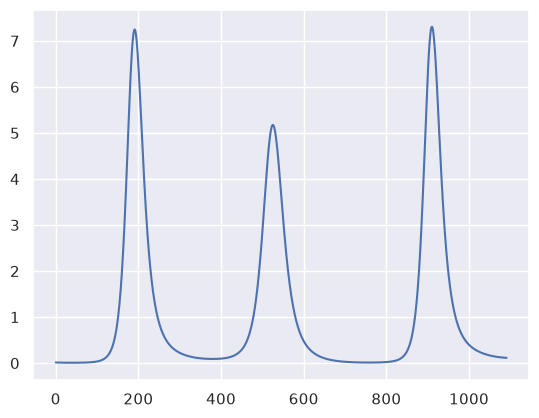

In [7]:
# --- Simulate Data ---

sim = seirs_beta_t_omega_s_ode_model(0.3, 1/2, 1/5, true_log_omega_s, -0.2, 0, season_bounds, season_bounds[-1])

burn_in_index = np.searchsorted(sim.times, season_bounds[20])
times_burn = sim.times[burn_in_index:]
states_burn = sim.states[burn_in_index:]

sim_df = pd.DataFrame({
    "time": times_burn - season_bounds[20],
    "S": states_burn[:, 0, 0],
    "E": states_burn[:, 0, 1],
    "I": states_burn[:, 0, 2],
    "R": states_burn[:, 0, 3]
})

plt.plot(sim_df["time"], sim_df["I"])

---
# MCMC Setup